### Does an HMM regime filter, estimated strictly out-of-sample, improve the net risk-adjusted performance and drawdown of rule-based S&P 500 strategies beyond what simple volatility or VIX rules achieve?

## 1. Data Collection

I download daily S&P 500 index data (`^GSPC`) from Yahoo Finance with `yfinance`, from  January 2000 to  December 2024 , which gives 6,288 trading days. The raw download is saved to `hmm_dataset.csv`. `yfinance` returns a two-level column index (price field and ticker), so I drop the ticker level and keep five columns: `Close`, `High`, `Low`, `Open` and `Volume`. 

I then download the VIX (`^VIX`) over the same period. The VIX is the market's expected 30-day volatility, quoted in percentage points. I take the log of its closing level, align it to the S&P 500 trading dates and forward-fill the few days where the VIX has no value, and store the result as `log_vix`.

In [163]:
import yfinance as yf

df = yf.download("^GSPC", start="2000-01-01", end="2024-12-31")
hmm_set=df.to_csv('hmm_dataset.csv',index=False)
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


len(df)
df.columns
df.columns=df.columns.droplevel('Ticker')
df.columns

[*********************100%***********************]  1 of 1 completed


Index(['Close', 'High', 'Low', 'Open', 'Volume'], dtype='object', name='Price')

In [164]:
vix = yf.download("^VIX", start="2000-01-01", end="2024-12-31")
vix.columns = vix.columns.droplevel('Ticker')
df['log_vix'] = np.log(vix['Close'].reindex(df.index).ffill())

[*********************100%***********************]  1 of 1 completed


## 2. Exploratory Analysis: Daily Returns

From the closing price I compute two series: the daily change in index points (`ret_no`) and the daily log return (`ret`), which is ln(P_t / P_{t-1}).I  print the skewness and excess kurtosis of the log returns and plot their histogram with a density curve.

Skewness measures how lopsided a distribution is: a negative value means the large moves are more often drops than rallies. Excess kurtosis measures how heavy the tails are: a positive value means extreme days happen more often than a bell curve predicts. A normal distribution scores 0 on both.

Daily log returns have a skewness of -0.386 and an excess kurtosis of 10.404; a normal distribution scores 0 on both. The negative skewness means large moves are somewhat more often drops than rallies, and the high kurtosis means extreme days occur far more often than a bell curve allows. A single normal distribution therefore fits these returns poorly.

skew -0.386 | ex kurtosis 10.404


<Axes: xlabel='Close', ylabel='Density'>

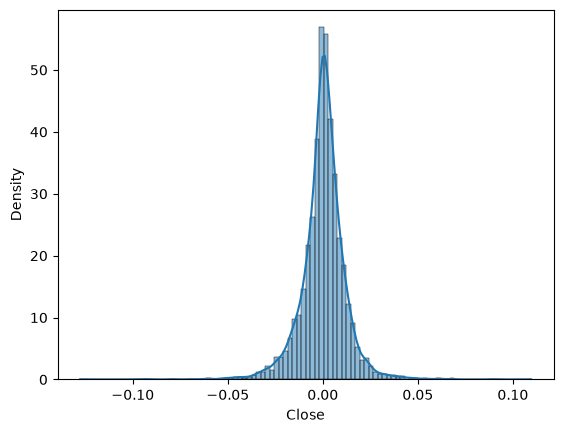

In [234]:
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
ret_no=df['Close'].diff().dropna()
ret = np.log(df['Close']).diff().dropna()
print('skew', round(ret.skew(), 3), '| ex kurtosis', round(ret.kurt(), 3))
sns.histplot(ret, kde=True, stat='density', bins=100)

## 2.2  Exploratory Analysis: Counting Extreme Days

This cell counts the extreme days directly. It computes the standard deviation of the log returns (`s`). For k = 3, 4 and 5, it counts the days where the absolute return is more than k standard deviations (`obv`). It then works out how many such days a normal distribution would give over the same number of observations (`exp`), which is the sample size times the probability of landing beyond ±k standard deviations. Finally, it runs a Jarque-Bera test, which checks whether the skewness and kurtosis are consistent with a normal distribution.

 Extreme days are far more common than a normal distribution allows:

| Threshold | Observed days | Expected days if normally distributed |
|---|---|---|
| beyond 3 sd | 100 | 17.0 |
| beyond 4 sd | 40 | 0.4 |
| beyond 5 sd | 21 | 0.004 |

There are about 6 times as many 3-sd days as expected, about 100 times as many 4-sd days, and thousands of times as many 5-sd days. The further out the threshold, the bigger the gap, which is what fat tails look like. I then run a Jarque-Bera test, which checks whether the skewness and excess kurtosis are close enough to a normal distribution's (both 0) to be due to chance. The statistic is 0 for a perfectly normal distribution and grows as skewness and kurtosis move away from 0. The result is 28,461 with a p-value of effectively 0, so normality is rejected. With over 6,000 observations the test rejects almost any real data, so the counts above are the stronger evidence.

In [180]:
s=ret.std()
for k in [3,4,5]:
    obv=(ret.abs()>k*s).sum()
    exp=len(ret)*2*(1-stats.norm.cdf(k))
    print(f'{k}_num_extreme_days',obv,f'exp_val_{k}',exp)
print(stats.jarque_bera(ret))

3_num_extreme_days 100 exp_val_3 16.97361784971692
4_num_extreme_days 40 exp_val_4 0.3982341948096506
5_num_extreme_days 21 exp_val_5 0.0036043568653665314
SignificanceResult(statistic=np.float64(28461.098461160982), pvalue=np.float64(0.0))


## Exploratory Analysis: QQ Plot

This cell draws a QQ (quantile-quantile) plot of the daily log returns. A QQ plot checks whether data follows a chosen distribution, here the normal. It sorts the returns from the lowest to the highest and plots each one against the value a perfect normal distribution would have at the same position in the sorted list. The red line shows where the points would fall if the returns were exactly normal. Points on the line mean the data is normal at that position, and points off the line show where it is not.

 The points follow the line only in the middle, roughly between -2 and +2 standard deviations. At both ends they bend sharply away from it. On the left, the worst days are far lower than a normal distribution allows, and on the right the best days are far higher. This S-shape is the signature of heavy tails on both sides, and the left tail is the longer one. It agrees with the kurtosis and the extreme-day counts. The correlation between the points and the line is 0.948, well below the near-1 value that normal data of this size would give.

((array([-3.69430437, -3.46249073, -3.3349007 , ...,  3.3349007 ,
          3.46249073,  3.69430437], shape=(6287,)),
  array([-0.1276522 , -0.09994485, -0.09469512, ...,  0.08968323,
          0.10245736,  0.10957197], shape=(6287,))),
 (np.float64(0.01160754481554554),
  np.float64(0.00022283614587296978),
  np.float64(0.9482925869623726)))

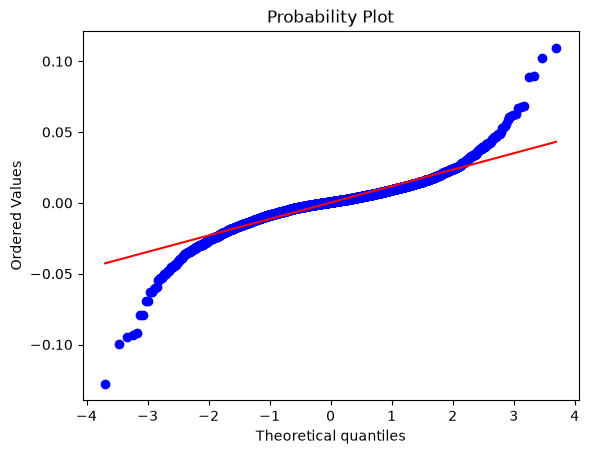

In [176]:
stats.probplot(ret,plot=plt)

## 2.3  Exploratory Analysis: Return Distribution Against a Normal Curve

This cell plots a histogram of the daily log returns on a density scale, with a smoothed curve (`kde=True`) drawn through it. A density histogram is scaled so its total area is 1, which lets it be compared with a probability curve. The smoothed curve is a kernel density estimate (KDE), a smooth estimate of the shape of the data. I add a dashed green line, the normal distribution with the same mean and standard deviation as the returns, evaluated at 300 evenly spaced points. Because the mean and spread(Std) match, any difference in shape comes from the data not being normal.

The returns are much more peaked than the normal curve: the density at zero is roughly 55, against roughly 33 for the normal. The tails are also heavier. Beyond about 0.05 in either direction the normal curve is almost flat at zero, while the data still reach about -0.13 on the downside and +0.11 on the upside. This matches the skewness and kurtosis numbers: most days are quieter than a normal distribution predicts, and a few days are far more extreme.

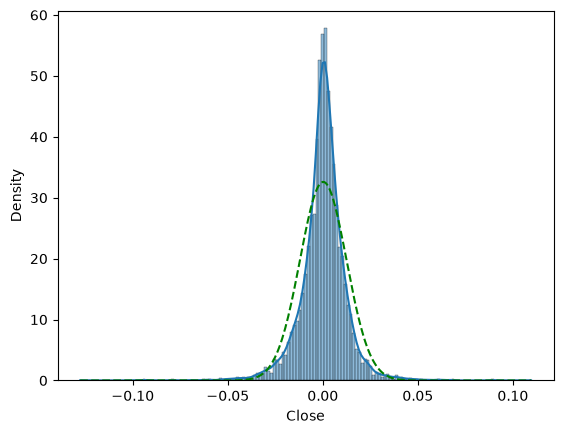

In [173]:
sns.histplot(ret,kde=True,stat='density')
x= np.linspace(ret.min(),ret.max(),300)
plt.plot(x,stats.norm.pdf(x,ret.mean(),ret.std()),'g--',label='normal')

## 2.4  Exploratory Analysis: Returns by Year

This cell splits the log returns into two periods, 2000-2011 (`ye`) and 2012-2024 (`ye2`), and draws a box plot of the daily returns for each calendar year. The whiskers extend to the most extreme days that are not unusual, and each dot is an unusually large move. The box height is  a simple measure of how much returns vary in that year.

 The median return is close to zero in every year, but the spread changes a lot. The boxes are tall in 2000-2002 and 2008-2009 and narrow in 2004-2006 and 2017. The most extreme days cluster in a few years: 2008 has outliers of roughly -0.09 and +0.11, and 2020 has a cluster reaching roughly -0.13 and +0.09. Volatility is not constant, and it comes in persistent stretches, with calm years and turbulent years. This is the exact  behaviour a regime model tries to capture: the extreme days come from a few turbulent periods, not evenly from all years.

<Axes: xlabel='Date'>

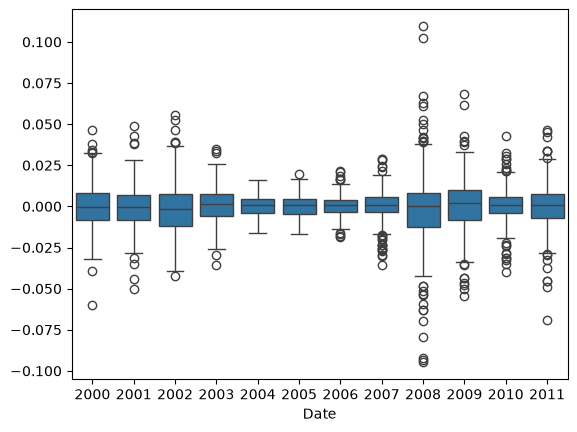

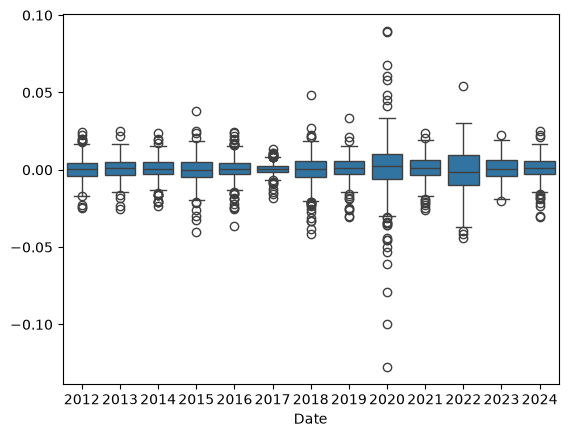

In [246]:
ye=ret.loc[:'2012-01-01']
ye2=ret.loc['2012-01-01':]
plt.figure()
sns.boxplot(x=ye.index.year,y=ye.values)
plt.figure()
sns.boxplot(x=ye2.index.year,y=ye2.values)

## 2.5 Exploratory Analysis: Rolling Volatility

This cell plots the volatility of the market over time. For each day it takes the standard deviation of the last 20 daily log returns (`ret.rolling(20).std()`). Volatility here means how much returns vary from day to day, so a higher value means a more turbulent market. The window is 20 trading days, roughly one month, so each point describes the recent past and not just one day. The result is multiplied by `np.sqrt(252)` to annualise it, which turns a daily figure into a yearly one. There are about 252 trading days in a year.

 Volatility is not constant. It sits mostly between 0.05 and 0.30, with calm stretches near 0.05 (around 2017), and it jumps sharply during crises: about 0.5 in 2002, about 0.85 in late 2008, about 0.5 in 2011 and close to 1.0 in March 2020. After each spike it decays gradually and does not drop straight back, so turbulent periods last for weeks or months. This is volatility clustering, and it supports the idea that the market moves between a calm state and a turbulent one. It is also the kind of measure that a simple volatility rule can use to decide when to stay out of the market.

Text(0, 0.5, 'annualised volatility (20-day)')

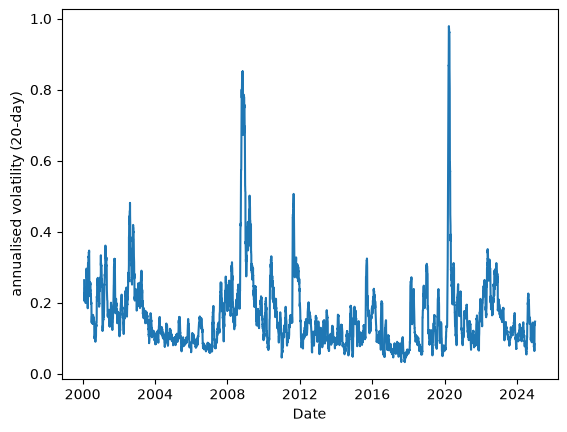

In [247]:
sns.lineplot(ret.rolling(20).std()*np.sqrt(252))
plt.ylabel('annualised volatility (20-day)')

## 2.6 Exploratory Analysis: Daily Returns Over Time

This cell plots the daily log return for every trading day from 2000 to 2024. Each point is one day's return. The line wiggles around zero, because gains and losses roughly cancel, and the height of the wiggle at any date shows how big the daily moves were then.

This agrees with the rolling volatility chart: the daily moves are large in 2000-2003, 2008-2009 and 2020, and small in between. The biggest days sit in those periods, so the extreme returns come from a few turbulent episodes and not from the whole sample.

Text(0, 0.5, 'daily log return')

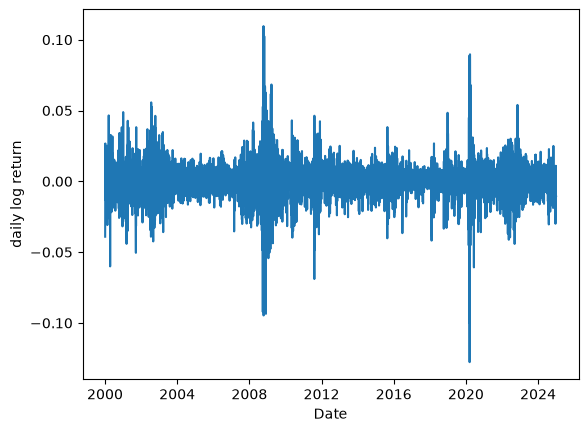

In [248]:
sns.lineplot(ret)
plt.ylabel('daily log return')

## 2.7  Exploratory Analysis: Autocorrelation of Absolute Returns

This cell measures how strongly the size of a day's move is related to the size of the moves in the days before it. Autocorrelation is the correlation of a series with a delayed copy of itself, and the delay is called the lag. A lag of 1 compares each day with the previous day, a lag of 5 compares it with the day five days earlier, and so on. I use absolute returns, which ignore the direction of the move and keep only its size, so the result is about volatility and not about direction. It computes the autocorrelation at every lag from 1 to 40 (`ret.abs().autocorr(l)`) and draws each as a bar. The red dashed lines are an approximate 95% band, calculated as 1.96 divided by the square root of the number of observations. Bars inside the band are consistent with no autocorrelation, and bars outside it are statistically meaningful.

Every one of the 40 bars is far above the band. The autocorrelation is about 0.29 to 0.38 at the first few lags and declines slowly, still near 0.17 at lag 40. A large move today is therefore linked to large moves for the next two months, and the effect fades only gradually. This is volatility clustering, and it means volatility is persistent enough to be estimated from recent data, which is the reason to use a volatility-based signal and regimes that last for a while.

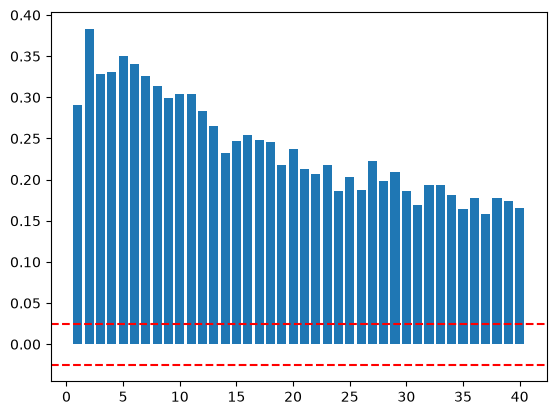

In [184]:
lags=range(1,41)
band = 1.96 / np.sqrt(len(ret))
plt.bar(lags,[ret.abs().autocorr(l) for l in lags])
plt.axhline(band, color='r', ls='--'); plt.axhline(-band, color='r', ls='--')



## 3. Feature Engineering

This cell defines a function, `feat(df)`, that builds all candidate features from the closing price and the VIX. It works on a copy of the data, so the original table is not changed. Every feature at a given date uses only that day and earlier days, so nothing looks into the future.

- **`log_returns`**: the daily log return, ln(P_t / P_{t-1}).
- **`realised_vol`**: the standard deviation of the last 20 daily log returns, annualised by multiplying by the square root of 252. Realised volatility is how much the market actually moved recently. At the end of the function it is replaced by `log1p` of itself, ln(1 + x), a transform that compresses large spikes.
- **`log_vix`**: the log of the VIX closing level, aligned to the S&P 500 trading dates, with missing days filled forward from the last value. The VIX is the market's expected volatility over the next 30 days, so it is forward-looking, while realised volatility looks backward.
- **`drawdown_252`**: how far the index is below its highest close of the past 252 trading days (about one year), as a fraction: (Close − rolling max) / rolling max. It is 0 at a new high and negative below it, for example −0.20 means 20% under the peak.
- **`cum60_log`, `cum20_log`, `cum5_log`**: the log return over the last 60, 20 and 5 trading days, ln(P_t / P_{t-n}). These measure the recent trend at three horizons: roughly a quarter, a month and a week.

The function is applied to the whole price history (`df=feat(df)`). The first rows of the longer-window features are empty (`NaN`) because the window is not yet full, and these rows are dropped before modelling.

In [186]:
def feat(df):
    df=df.copy()
    df['log_returns']=np.log(df['Close']/df['Close'].shift(1))
    df['realised_vol']=df['log_returns'].rolling(window=20).std()*np.sqrt(252)
    df['log_vix'] = np.log(vix['Close'].reindex(df.index).ffill())
    rol_max=df['Close'].rolling(window=252,min_periods=1).max()
    df['drawdown_252']=(df['Close']-rol_max)/rol_max
    df['cum60_log']=np.log(df['Close']/df['Close'].shift(60))
    df['cum20_log']=np.log(df['Close']/df['Close'].shift(20))
    df['cum5_log']=np.log(df['Close']/df['Close'].shift(5))
    df['realised_vol']=np.log1p(df['realised_vol'])
    return df
df=feat(df)
df

Price,Close,High,Low,Open,Volume,log_vix,log_returns,realised_vol,drawdown_252,cum60_log,cum20_log,cum5_log
Date,,,,,,,,,,,,
2000-01-03,1455.219971,1478.000000,1438.359985,1469.250000,931800000,3.186766,NaN,NaN,0.000000,NaN,NaN,NaN
2000-01-04,1399.420044,1455.219971,1397.430054,1455.219971,1009000000,3.296207,-0.039099,NaN,-0.038345,NaN,NaN,NaN
2000-01-05,1402.109985,1413.270020,1377.680054,1399.420044,1085500000,3.273743,0.001920,NaN,-0.036496,NaN,NaN,NaN
2000-01-06,1403.449951,1411.900024,1392.099976,1402.109985,1092300000,3.247658,0.000955,NaN,-0.035575,NaN,NaN,NaN
2000-01-07,1441.469971,1441.469971,1400.729980,1403.449951,1225200000,3.078233,0.026730,NaN,-0.009449,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-23,5974.069824,5978.250000,5902.569824,5940.250000,3593280000,2.820188,0.007261,0.126801,-0.019080,0.040288,0.000792,-0.016602
2024-12-24,6040.040039,6040.100098,5981.439941,5984.629883,1757720000,2.658159,0.010982,0.131357,-0.008248,0.047043,0.008758,-0.001748
2024-12-26,6037.589844,6049.750000,6007.370117,6024.970215,2904530000,2.689886,-0.000406,0.130153,-0.008650,0.056005,0.002647,0.027782


## 3.4 Feature Selection, Train/Test Split and Standardisation

This cell prepares the data for the model in four steps.

1. **Choose the features.** `cols` lists the seven model inputs: `log_vix`, `cum60_log`, `cum20_log`, `cum5_log`, `realised_vol`,`drawdown_252` and `log_returns`. Two of them describe market stress, one is implied volatility (VIX) and the other realised volatility, and three describe the trend at 60, 20 and 5 days. 
2. **Drop incomplete rows.** `dropna()` removes the days where any feature is missing. These are the first days of the sample, before the longest window (60 days) is full.
3. **Split in time order.** The first 80% of the rows form the training set and the last 20% form the test set. The split is by position and the rows are never shuffled. Shuffling would mix future days into the training data, so the model could learn from information it would not have had at the time.
4. **Standardise.** `StandardScaler` rescales each feature to a mean of 0 and a standard deviation of 1. This is needed because the features sit on very different scales (`log_vix` is around 3, while a daily return is around 0.01), and without it the large-valued features would dominate the fit. The scaler learns the mean and standard deviation from the training set only (`fit_transform`). The test set is then rescaled with those same numbers (`transform`). Letting the scaler fit the test set would leak information about the later period into the model.

The result is two tables, `X_tra` (training) and `X_test` (test), with the original dates as their index. 

In [254]:
from sklearn.preprocessing import StandardScaler
cols = ['log_vix','cum60_log','cum20_log','cum5_log','realised_vol','log_returns','drawdown_252']
X=df[cols].dropna()
X_idx=X.index
split=int(len(X)*0.8)
train=X.loc[X.index[:split]]
test=X.loc[X.index[split:]]
sca=StandardScaler()
X_tra=pd.DataFrame(sca.fit_transform(train),columns=cols,index=train.index)
X_test=pd.DataFrame(sca.transform(test),columns=test.columns,index=test.index)

## 3.5 Correlation Matrix (Training Set)

This cell prints the correlation matrix of the standardised training features, rounded to two decimals. Correlation measures how closely two series move together in a straight line, from +1 (they rise and fall together) through 0 (no straight-line relationship) to -1 (one rises when the other falls). Standardising does not change correlations, and the matrix uses the training period only, so it can inform feature choices without using the test years.

- **Market stress:** `log_vix`, `realised_vol` and `drawdown_252` are strongly related to each other (0.86, -0.83 and -0.78). They are three views of the same thing, how stressed the market is, so they add little new information when used together.
- **Trend:** `cum60_log`, `cum20_log` and `cum5_log` are moderately related (0.56, 0.48 and 0.29), because the shorter windows sit inside the longer ones. The 60-day trend is also related to stress (-0.66 with `realised_vol`, -0.59 with `log_vix`, 0.59 with `drawdown_252`), meaning that volatility tends to be high when the market has been falling.
- **Daily return:** `log_returns` is almost unrelated to the stress measures (-0.01 with `realised_vol`, -0.13 with `log_vix`) and is related only to the 5-day return (0.43), which contains it. 
The model treats features within a state as independent (diagonal covariance), so strongly overlapping features have their evidence counted more than once. This is a limitation of the model and is the reason for keeping independant features

In [255]:
X_tra.corr().round(2)

,log_vix,cum60_log,cum20_log,cum5_log,realised_vol,log_returns,drawdown_252
log_vix,1.00,-0.59,-0.43,-0.26,0.86,-0.13,-0.83
cum60_log,-0.59,1.00,0.56,0.29,-0.66,0.13,0.59
cum20_log,-0.43,0.56,1.00,0.48,-0.38,0.22,0.36
cum5_log,-0.26,0.29,0.48,1.00,-0.07,0.43,0.19
realised_vol,0.86,-0.66,-0.38,-0.07,1.00,-0.01,-0.78
log_returns,-0.13,0.13,0.22,0.43,-0.01,1.00,0.09
drawdown_252,-0.83,0.59,0.36,0.19,-0.78,0.09,1.00


## 3.6 Final Feature Set

This cell defines a small function, `drop_cols`, that takes a table of features, makes a copy and removes three columns: `drawdown_252`, `realised_vol` and `log_returns`. It is applied to both the training table (`X_tra`) and the test table (`X_test`), so both end up with the same columns. Because the features were already standardised column by column, dropping columns after scaling does not change the values in the remaining ones.

The correlation matrix  is the reason for the choice:
- `realised_vol` (0.86 with `log_vix`) and `drawdown_252` (-0.83 with `log_vix`) are almost the same signal as the VIX, so they would add little that is new. The VIX is kept because it is forward-looking, whereas realised volatility looks backward.
- `log_returns` is a single day's move. It has almost no relationship with the stress measures and is already contained in the 5-day return.

The model therefore uses four features: `log_vix`, which measures expected market stress, and `cum60_log`, `cum20_log` and `cum5_log`, which measure the trend over the last quarter, month and week. The three trend features overlap somewhat (correlations of 0.29 to 0.56), but they capture direction at different horizons.

In [256]:
def drop_cols(df):
    df=df.copy()
    df=df.drop(columns=['drawdown_252','realised_vol','log_returns'])
    return df
X_tra,X_test=drop_cols(X_tra),drop_cols(X_test)

### 4.1 Choice of K = 5

Before looking at the table, I set a rule: choose the K with the lowest BIC among the values where every state holds at least 10% of the training days and the lowest self-transition probability is at least 0.90. A self-transition probability of 0.90 means a state lasts about 1 / (1 − 0.90) = 10 trading days on average.

K = 2 to 5 pass both conditions. BIC falls at every K, so among the values that pass, the lowest BIC is always the largest one, which is K = 5. The rule therefore selects K = 5, but it is the size and persistence thresholds that stop the search, not BIC.

K = 5 is also consistent with two other diagnostics. The two best random starts agree almost perfectly (adjusted Rand index 0.997), and the validation log-likelihood on days the model was not fitted on improves up to K = 5. It dips at K = 6 and improves again at K = 7 and K = 8, but those models are excluded by the rule: their smallest states hold 7.2% and 6.1% of the days, and their states last less than 10 days on average. The agreement between random starts is also lower at K = 6 (0.709) and K = 8 (0.562), so those solutions depend more on the starting point.

**Limits of this choice.** AIC and BIC have no elbow, so they cannot choose K on their own, and the result depends on the 10% and 0.90 thresholds, which are judgements. A threshold of 0.95 would select K = 3. The least persistent state at K = 5 has a self-transition probability of 0.929, which is an average duration of about 14 trading days.

In [195]:
from hmmlearn.hmm import GaussianHMM
from sklearn.metrics import adjusted_rand_score

# ---- rule, fixed BEFORE looking at the table ----
MIN_FRAC, MIN_PERSIST, N_SEEDS = 0.10, 0.90, 10
K_RANGE = range(2, 9)

bic_spl = int(len(X_tra.index) * 0.8)
tr = X_tra.iloc[:bic_spl]
va = X_tra.iloc[bic_spl:]            # validation block inside the training period, not the test set

def n_params(k, d):                  # diag covariance
    return (k - 1) + k * (k - 1) + 2 * k * d

models, rows = {}, []
for k in K_RANGE:
    fits = []
    for seed in range(N_SEEDS):
        m = GaussianHMM(n_components=k, covariance_type='diag',
                        n_iter=500, tol=1e-3, random_state=seed).fit(tr)
        fits.append((m.score(tr), m))
    fits.sort(key=lambda t: -t[0])
    best_ll, best_m = fits[0]
    models[k] = best_m
    p, n_obs = n_params(k, tr.shape[1]), len(tr)
    lab = best_m.predict(tr)
    rows.append({'k': k,
                 'train_ll': best_ll,
                 'AIC': -2 * best_ll + 2 * p,
                 'BIC': -2 * best_ll + p * np.log(n_obs),
                 'val_ll': best_m.score(va),
                 'min_state_frac': np.bincount(lab, minlength=k).min() / n_obs,
                 'min_persistence': np.diag(best_m.transmat_).min(),
                 'seed_ARI': adjusted_rand_score(lab, fits[1][1].predict(tr)),
                 'converged': best_m.monitor_.converged})

sel = pd.DataFrame(rows).set_index('k')
sel['dBIC'] = sel['BIC'].diff()
sel.round(3)

,train_ll,AIC,BIC,val_ll,min_state_frac,min_persistence,seed_ARI,converged,dBIC
k,,,,,,,,,
2,-18070.766,36179.532,36299.047,-3514.732,0.386,0.979,1.000,True,NaN
3,-16285.368,32634.736,32836.025,-3000.153,0.200,0.965,1.000,True,-3463.022
4,-15047.920,30189.841,30485.484,-2730.329,0.221,0.925,1.000,True,-2350.541
5,-13957.894,28043.788,28446.367,-2649.589,0.136,0.929,0.997,True,-2039.117
6,-13192.003,26550.006,27072.101,-2669.975,0.086,0.935,0.709,True,-1374.266
7,-12621.146,25450.293,26104.483,-2521.334,0.072,0.879,0.965,True,-967.617
8,-12181.338,24616.677,25415.544,-2403.681,0.061,0.895,0.562,True,-688.939


### 4.2 Final model fit

With K = 5 fixed in Section 4.1, I fit the final HMM on the training period only (`X_tra`). The model has a diagonal covariance, so each state describes the features with a mean and a separate variance for each one, and it was fitted with up to 500 EM iterations and a convergence tolerance of 1e-3.

EM can end in a poor local optimum, so I fitted the model from 10 random starting points (seeds 0 to 9) and kept the one with the highest log-likelihood on the **training** data. The test data played no part in this choice. The best start was seed 4, with a training log-likelihood of -16,486.19.

The fitted model was then applied to the test period to label each day (`predict`). The test period contains 1,246 days. The state counts are: state 0 = 151, state 1 = 497, state 2 = 201, state 3 = 195, state 4 = 202.

**What these labels are for.** `predict` uses the Viterbi algorithm, which chooses the most likely sequence of states for the whole test period at once. A day's label can therefore depend on days that come after it. I use these labels only to describe the states (their size, their return distribution, and the kurtosis checks in Section 4.3). They are not used to trade. The strategy filter in the backtest uses forward-filtered probabilities from the walk-forward procedure, where each day's regime comes from a model fitted on earlier data only.

**Limits of this fit.**
- State numbers are arbitrary labels from the fit. They carry no order, so I order the states by their average VIX when I describe them (calm to stressed).
- The model is fitted once on the training period. In the walk-forward backtest, it is refitted on an expanding window, so the states in this section will not be identical to the ones used in the backtest.
- The test block is a single stretch of 1,246 days, and state 1 holds 40% of it, so these counts describe that period and do not say how common each state is over the full history.

In [196]:
from hmmlearn.hmm import GaussianHMM

final_model = GaussianHMM(n_components=5, covariance_type='diag',
                           n_iter=200, tol=1e-2, random_state=0)  # try the seed that gave best_ll for n=7, or just refit with a few seeds and pick best
best_ll = -np.inf
best_seed = None
for seed in range(10):
    m = GaussianHMM(n_components=5, covariance_type='diag', n_iter=500, tol=1e-3, random_state=seed)
    m.fit(X_tra)
    ll = m.score(X_tra)   # FIX: select seed on TRAIN, not test
    if ll > best_ll:
        best_ll = ll
        best_seed = seed
        final_model = m

print(f"Best seed: {best_seed}, train log-lik: {best_ll}")

states = final_model.predict(X_test)
print(pd.Series(states).value_counts().sort_index())

Best seed: 4, train log-lik: -16486.192851629385
0    151
1    497
2    201
3    195
4    202
Name: count, dtype: int64


### 5. Loading the 2025 data

The main design is fixed in Sections 4.1 and 4.2. To extend the study, I downloaded daily data for the S&P 500 (`^GSPC`) and the VIX (`^VIX`) from 1 January 2000 to 30 August 2026 using `yfinance`. The start date is the same as in the earlier run, so every fold in the walk-forward uses the same training history as before.

The VIX is aligned to the S&P 500's trading days, and on a day when the VIX is missing, the last available value is carried forward. The model input is the log of the VIX, built from that aligned series. The other features are computed from the S&P 500 close in the same way as in the earlier data.

**What was fixed before loading.** K = 5 states, a diagonal covariance, and an expanding-window walk-forward with an initial training period of 8 years and a refit every 252 days. The stress rule is that the two states with the highest VIX in each fold's training data count as stress, and a strategy is switched off when their combined filtered probability is 0.5 or higher. The strategies (breakout, Bollinger, trend, RSI), the two baseline filters (VIX below 20, and 20-day volatility), the 5 bps cost per unit traded, and the metrics (Sharpe, annual return, maximum drawdown, PSR and DSR) were also fixed. None of these were changed after the new data was loaded.

**How the new data is used.** The walk-forward is an expanding window, so each fold depends only on earlier data. Adding data at the end adds new folds and leaves the earlier folds unchanged. I rerun the identical code on the extended data and report three results: the period up to 2026, 2020 to 2024, and true untouched holdout period (2025-2026). The DSR trial count stays the same, because no variant was added.

**Limits of this extension.**
- The 2025-onwards block is short, about 1.7 years of trading days,
- It contains the volatility spike of April 2025, which is a single episode, so it counts as one piece of evidence and not several.
- Free price data can be revised after the fact. Before reading the 2025 results, I compare the regime probabilities from the earlier run with the same dates in the extended run, and any difference is reported.
- The end date is a cut-off I chose once, and it was not changed after seeing results.

In [203]:
df_2025 = yf.download("^GSPC", start="2000-01-01", end="2026-08-30",)
df_2025.columns=df_2025.columns.droplevel('Ticker')
vix = yf.download("^VIX", start="2000-01-01", end="2026-08-30")
vix.columns = vix.columns.droplevel('Ticker')
df_2025['log_vix'] = np.log(vix['Close'].reindex(df_2025.index).ffill())
df25=feat(df_2025)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [205]:
df25

Price,Close,High,Low,Open,Volume,log_vix,log_returns,realised_vol,drawdown_252,cum60_log,cum20_log,cum5_log
Date,,,,,,,,,,,,
2000-01-03,1455.219971,1478.000000,1438.359985,1469.250000,931800000,3.186766,NaN,NaN,0.000000,NaN,NaN,NaN
2000-01-04,1399.420044,1455.219971,1397.430054,1455.219971,1009000000,3.296207,-0.039099,NaN,-0.038345,NaN,NaN,NaN
2000-01-05,1402.109985,1413.270020,1377.680054,1399.420044,1085500000,3.273743,0.001920,NaN,-0.036496,NaN,NaN,NaN
2000-01-06,1403.449951,1411.900024,1392.099976,1402.109985,1092300000,3.247658,0.000955,NaN,-0.035575,NaN,NaN,NaN
2000-01-07,1441.469971,1441.469971,1400.729980,1403.449951,1225200000,3.078233,0.026730,NaN,-0.009449,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
2026-08-24,7652.859863,7670.299805,7638.169922,7663.379883,4400800000,2.763170,-0.002807,0.124529,-0.018737,0.011728,0.031820,-0.011976
2026-08-25,7677.279785,7686.109863,7650.919922,7676.660156,4260240000,2.737609,0.003186,0.124627,-0.015606,0.012744,0.032904,-0.001884
2026-08-26,7675.700195,7690.729980,7657.410156,7666.879883,4100600000,2.721953,-0.000206,0.110737,-0.015808,0.009917,0.047975,-0.004197


### 4.4 Forward-filtered state probabilities

The strategy filter needs a regime estimate for each day that uses only the data up to that day. `predict` and `predict_proba` cannot give this, because both use the whole sequence, so a day's state can depend on days after it. I therefore wrote my own function, `filtered_probs`, which runs the forward algorithm.

**What the function does.** For each day, it takes yesterday's probability of each state, moves it forward one day with the transition matrix, and then multiplies it by how likely today's features are under each state (the Gaussian density with that state's mean and covariance). The results are divided by their sum, so the five probabilities add up to 1. In steps:

1. On the first day, the probabilities start from the model's start probabilities.
2. On each later day, `a = (previous probabilities @ transition matrix) * likelihood of today's data`.
3. The probabilities for the day are `a / a.sum()`.

Because each row is normalised, the likelihoods can be rescaled by subtracting the row maximum before taking the exponential. This avoids underflow and does not change the result. The function also uses `allow_singular=True`, so a state with a very small variance does not cause an error.

**How it is used in the backtest.** The model is fitted on the training window of each fold and its parameters are then held fixed. The function runs over the training window's last 250 days (a warm-up) followed by the next block, and the warm-up rows are discarded. The warm-up lets the probabilities settle, so the first day of the block does not depend on the start probabilities. The probability of the two highest-VIX states on day t uses data up to and including day t. The backtest engine then shifts the position by one day, so the position held on day t+1 is based on information available at the close of day t.

**Limits.**
- The probabilities are only as good as the fitted model. They are filtered estimates from a model with fixed parameters, and the model has not seen the block it is scoring.
- The filtered probability reacts later to a change of regime than the smoothed one, because it cannot use the days that confirm the change. This is the price of using only past data, and it is one reason a filter built on it can lag a simple rule such as trailing volatility.
- The warm-up of 250 days is a choice. A shorter warm-up leaves more influence from the start probabilities on the first days of each block.
- The function assumes the diagonal covariance used in the fit, which `hmmlearn` returns as full matrices through `covars_`.

In [208]:
from scipy.stats import multivariate_normal

def filtered_probs(model, X):
    K = model.n_components
    logB = np.column_stack([
        multivariate_normal.logpdf(X, model.means_[k], model.covars_[k], allow_singular=True)
        for k in range(K)
    ])
    B = np.exp(logB - logB.max(axis=1, keepdims=True))
    A = model.transmat_
    out = np.zeros((len(X), K))
    a = model.startprob_ * B[0]
    out[0] = a / a.sum()
    for t in range(1, len(X)):
        a = (out[t - 1] @ A) * B[t]       # yesterday's belief -> transition -> today's data
        out[t] = a / a.sum()
    return out

### 4.5 Walk-forward regime estimation

The regime used by the backtest comes from a walk-forward procedure, where every day's regime is produced by a model that has only seen earlier data. The features are four series built from the S&P 500 and the VIX: log VIX and the cumulative log returns over 60, 20 and 5 days. The model is the K = 5 HMM from Section 4.1, with a diagonal covariance.

**What the code does.** The procedure works in yearly blocks.

1. The first training window is the first 8 years of data (`min_train` = 252 × 8 rows). After that, each block is the next 252 trading days (`step`).
2. For each block, a `StandardScaler` is fitted on the training data only (everything before the block), and the training data is standardised with it.
3. The HMM is fitted on the standardised training data from 10 random starting points (seeds 0 to 9), keeping the fit with the highest log-likelihood on the training data. A seed that raises an error is skipped. Each fit uses up to 500 EM iterations and a tolerance of 1e-3.
4. HMM states have arbitrary numbers, so I order the states of each fold by their average VIX (the fitted means are converted back to raw units with the scaler, and `log_vix` is the ordering column). Column 1 of the output is always the calmest state and column 5 the most stressed.
5. The filtered probabilities  are computed over the 250 days before the block plus the block itself, and the first 250 rows are dropped. These 250 days are a warm-up, so the first day of the block does not depend on the model's start probabilities.
6. The probabilities of the block are stored, and the next window expands by 252 days.

**The regime rule.** `p_stress` is the sum of the probabilities of the two highest-VIX states. The regime is 1 (trading allowed) when `p_stress` is below 0.5 and 0 (flat) otherwise. The regime is then aligned to the price index. A day with no regime estimate, such as the first 8 years, gets 0.

For each fold I also store the first date of the block, the average duration of each ordered state (1 divided by 1 minus its self-transition probability, in trading days) and its average VIX in index points. These are used in Section 4.6 to check that the ranks keep a similar meaning from fold to fold.

**Limits.**
- The stress rule is relative. "The two highest states" is defined fold by fold, so the VIX level of a stress state is not fixed. An early fold that has seen few crises may call a VIX of about 25 stress, and a later one may need more. The stored VIX levels show how much this moves.
- The model is refitted once a year, so within a block its parameters can be up to a year old, and the filter cannot adapt to a change in the market's behaviour inside the block.
- Ten random starts reduce the chance of a poor local optimum but do not remove it. I choose the start by its training log-likelihood, and the code does not record whether each fit converged.
- There is no regime for the first 8 years, so every filtered and unfiltered variant is scored from the first fold's date onwards, so all of them cover the same days.
- The last block can be shorter than 252 days.

In [296]:
from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler
cols=['log_vix','cum60_log','cum20_log','cum5_log']
feat=df25[cols].dropna()
def fit_hmm(X, k, seeds=10):
    best, best_ll = None, -np.inf
    for s in range(seeds):
        m = GaussianHMM(k, covariance_type='diag', n_iter=500, tol=1e-3,random_state=s)
        try: m.fit(X)
        except ValueError: continue
        ll = m.score(X)
        if ll > best_ll: best, best_ll = m, ll
    return best

def walk_forward(feat, k=5, vix_col='log_vix', min_train=252*8, step=252, warm=250):
    out, log = [], []
    for s in range(min_train, len(feat), step):
        train, block = feat.iloc[:s], feat.iloc[s:s+step]
        sc = StandardScaler().fit(train)                    # train only
        m = fit_hmm(sc.transform(train), k)
        raw_means = sc.inverse_transform(m.means_)
        order = np.argsort(raw_means[:, feat.columns.get_loc(vix_col)])   # calm -> stress
        ctx = feat.iloc[s-warm : s+len(block)]              # history gives a proper prior
        P = filtered_probs(m, sc.transform(ctx))[warm:][:, order]
        out.append(pd.DataFrame(P, index=block.index))
        log.append(dict(fold_start=block.index[0], dur=(1/(1-np.diag(m.transmat_)[order])).round(0),
                        vix=np.exp(raw_means[order, feat.columns.get_loc(vix_col)]).round(1)))
    return pd.concat(out), pd.DataFrame(log),m,sc

P, fold_log,mod,sc = walk_forward(feat)
p_stress = P.iloc[:, -2:].sum(axis=1)                        # top 2 states by VIX
regime = (p_stress < 0.5).astype(float).reindex(price.index).fillna(0)

In [297]:
regime.sample(50)

Date
2017-02-13    1.0
2008-09-05    0.0
2016-03-30    1.0
2001-07-10    0.0
2020-05-19    0.0
2004-05-11    0.0
2017-06-28    1.0
2006-08-24    0.0
2017-10-27    1.0
2014-01-15    1.0
2017-04-21    1.0
2026-08-03    1.0
2016-04-22    1.0
2017-06-26    1.0
2010-07-23    0.0
2024-05-28    1.0
2015-03-03    1.0
2013-04-08    1.0
2013-06-05    1.0
2008-12-19    0.0
2001-09-06    0.0
2014-10-09    1.0
2025-12-01    1.0
2025-10-06    1.0
2013-03-27    1.0
2012-06-21    1.0
2005-04-07    0.0
2001-04-04    0.0
2019-07-23    1.0
2003-05-14    0.0
2000-06-16    0.0
2007-08-13    0.0
2004-04-19    0.0
2011-02-14    1.0
2009-01-29    0.0
2024-07-09    1.0
2015-09-11    0.0
2020-08-26    1.0
2023-02-09    1.0
2009-01-23    0.0
2014-03-21    1.0
2008-04-30    1.0
2004-03-17    0.0
2014-07-02    1.0
2011-03-03    1.0
2020-04-07    0.0
2019-04-11    1.0
2023-01-13    1.0
2019-02-21    1.0
2007-10-30    0.0
dtype: float64

### 4.6 The regime filters

I compares three regime filters on the same strategies. Each filter is a function that returns a series of 1s and 0s for every day: 1 means the strategy is allowed to trade, and 0 means it stays flat. A filter does not change a strategy's direction. The backtest multiplies the strategy's position (+1, -1 or 0) by the filter, so a long or short position is either kept or set to 0, and a flat position stays flat. The engine then shifts the result by one day, so the position held on day t+1 is based on information available at the close of day t.

**VIX rule (`vix_pos`).** The filter is 1 when the VIX closes below 20 and 0 otherwise. A missing VIX gives 0. The level of 20 is a common convention for the long-run average of the VIX, and it is fixed and not tuned.

**Volatility rule (`vol_pos`).** The filter is 1 when the 20-day realised volatility of the S&P 500 is at or below its own 75th percentile, and 0 otherwise. Realised volatility is the standard deviation of the last 20 daily returns, multiplied by the square root of 252 to annualise it. The 75th percentile is computed on an expanding window, so on each day it uses only past values, and it needs at least 252 days of history before it produces a value (`min_obs` = 252). A day with no threshold gets 0, so this filter is also flat during its first year.

**HMM rule (`hmm_pos`).** The filter is 1 when the filtered probability that the market is in one of the 2 highest-VIX states is below 0.5, and 0 otherwise. The probabilities come from the walk-forward procedure in Section 4.5. A day with no HMM output, such as the first 8 years, gets 0.

All three filters are built from information available on the day itself. The VIX rule uses the day's VIX, the volatility rule uses returns up to that day with a past-only threshold, and the HMM rule uses forward-filtered probabilities from a model fitted on earlier data. None of them uses a future value.

 The three rules do the same job, which is to switch a strategy off in a stressed market. They differ in how they define stress: a fixed VIX level, the market's own recent volatility compared with its history, and a fitted model of regimes. This is what the research question tests. The simple rules are set before the backtest and are not tuned, so the HMM has to do better than rules that cost nothing to build.

**Limits.**
- The thresholds (VIX of 20, a 20-day window, the 75th percentile, 2 stress states and 0.5) are fixed choices. Another value would give a different result, and any change after seeing results would be another trial in the DSR.
- The three filters spend different shares of days invested, and a filter that is flat more often lowers drawdowns mechanically. The invested share is reported next to every result so this can be checked.
- Each filter is flat in its warm-up period (the first year for the volatility rule and the first 8 years for the HMM rule), so all variants are scored from the HMM's first date, which keeps them on the same days.
- The VIX and volatility rules are rules about the level of stress, while the HMM rule is about the model's belief.

In [298]:
def vix_pos(vix, level=20):
    pos = np.zeros(len(vix))
    for i in range(len(vix)):
        if np.isnan(vix.iloc[i]):
            continue
        pos[i] = 1 if vix.iloc[i] < level else 0
    return pd.Series(pos, index=vix.index)

def vol_pos(price, window=20, q=0.75, min_obs=252):
    rv  = price.pct_change().rolling(window).std() * np.sqrt(252)
    thr = rv.expanding(min_periods=min_obs).quantile(q)
    pos = np.zeros(len(price))
    for i in range(len(price)):
        if np.isnan(thr.iloc[i]) or np.isnan(rv.iloc[i]):
            continue
        pos[i] = 1 if rv.iloc[i] <= thr.iloc[i] else 0
    return pd.Series(pos, index=price.index)

def hmm_pos(P, index, n_stress=2, thresh=0.5):
    p_stress = P.iloc[:, -n_stress:].sum(axis=1)
    pos = np.zeros(len(index))
    for i, d in enumerate(index):
        if d not in p_stress.index:
            continue                            
        pos[i] = 1 if p_stress.loc[d] < thresh else 0
    return pd.Series(pos, index=index)

### Strategy 1: Bollinger bands (mean reversion)

The Bollinger strategy is a mean-reversion rule. It assumes that a price that moves unusually far from its recent average tends to move back towards it. Unlike breakout and trend, which follow a move, this strategy bets against it.

**What the code does.**

1. For every day, it computes the average close of the last 20 days (`ma`) and the standard deviation of those 20 closes (`sd`). The upper band is `ma + 2 × sd` and the lower band is `ma - 2 × sd`. The standard deviation is the sample version (the pandas default).
2. The position is a state that carries over from day to day. It starts flat (0). While flat, it goes **long (+1)** if the close is below the lower band, and **short (-1)** if the close is above the upper band.
3. A long position is held until the close is back at or above the moving average, and then it goes flat. A short position is held until the close is back at or below the moving average.
4. The first 19 days have no moving average, so the position stays 0 there. The function returns a series of +1, -1 and 0, indexed like the price.

A position is only closed at the moving average, so a trade can last several days. A long can never flip to a short in one step. It has to go through flat first, so each position change costs one unit of trading, and the engine charges 5 bps for it. As with every strategy in this study, the backtest shifts the position by one day, so the position held on day t+1 is based on the close of day t.

Short-term price moves partly reflect forced selling, panic and overreaction, and these tend to reverse. A strategy that buys when the price is far below its average and sells when it is far above can be paid for providing liquidity. It should fail when the move is not temporary, such as a strong trend or a crash, because the price keeps going and the position keeps losing.

The window is 20 days and the band width is 2 standard deviations. These are the conventional Bollinger settings. I fixed them before the backtest and did not tune them, because every other value I tried would be another trial in the Deflated Sharpe Ratio.

**Limits.**
- The bands use the standard deviation of the price level, and a width of 2 standard deviations is a meaningful threshold only if the tails are close to normal. Index returns are fat-tailed (Section 3), so a price can sit outside the band for a long time in a crash, and the strategy keeps adding to a losing position without a stop.
- The strategy earns small gains most of the time and takes large losses in sustained trends. This gives a negative skew and a high kurtosis in its returns, and Sharpe understates that risk. This is why PSR and maximum drawdown are reported next to it.
- It can be short a rising market for weeks, because a short stays open until the price falls back to the moving average.
- It is flat for a large part of the sample, and the share of days invested is reported with the results.
- The long and short sides are symmetric. The S&P 500 has a positive drift over the sample, which works against the short side.
- It trades more often than breakout and trend, so the 5 bps cost matters more for it.

In [299]:
def bollinger_pos(price, window=20, k=2.0):
    ma = price.rolling(window).mean()
    sd = price.rolling(window).std()
    upper, lower = ma + k * sd, ma - k * sd
    pos = np.zeros(len(price))
    for i in range(1, len(price)):
        if np.isnan(ma.iloc[i]):
            continue
        p, prev = price.iloc[i], pos[i - 1]
        if prev == 0:
            if p < lower.iloc[i]:   pos[i] = 1
            elif p > upper.iloc[i]: pos[i] = -1
        elif prev == 1:
            pos[i] = 0 if p >= ma.iloc[i] else 1
        else:
            pos[i] = 0 if p <= ma.iloc[i] else -1
    return pd.Series(pos, index=price.index)

## 5.1  Strategy 2: RSI Mean-Reversion Strategy

This cell defines the fourth strategy, `rsi_wilder`, which trades on the Relative Strength Index (RSI). The RSI is a momentum indicator between 0 and 100 that compares the size of recent up-days with the size of recent down-days. A low value means the price has mostly been falling and is called oversold, and a high value means it has mostly been rising and is called overbought.

**Computing the RSI.** The function takes the daily price change (`price.diff()`) and splits it into gains (`clip(lower=0)`, which keeps the positive changes) and losses (`-clip(upper=0)`, which keeps the size of the negative changes). Each is smoothed with an exponentially weighted average using `alpha = 1/n` with `n = 14`. This is Wilder smoothing, the original method of the RSI's inventor: each day's average is built from the previous average plus a small share of the new value, so recent days count more than old ones. The ratio of average gain to average loss is `rs`, and the index is `rsi = 100 - 100 / (1 + rs)`. If losses are small compared with gains the RSI is high, and if gains are small compared with losses it is low.

**Trading rules.** The strategy is mean-reverting, which means it bets that a price that has moved too far will move back. It loops through the days and keeps a position of 1 (long), 0 (cash) or -1 (short):

- **From cash:** go long when the RSI falls below 30 (`lo`) and short when it rises above 70 (`hi`).
- **While long:** stay long until the RSI climbs back to 50 (`exit_`), then move to cash.
- **While short:** stay short until the RSI drops back to 50, then move to cash.
- **Warm-up:** days where the RSI is not yet defined are skipped, and the position stays at 0.

The parameters (14-day window, 30/70 entry levels and 50 exit level) are the standard textbook values. I did not tune them. As with the other strategies, the position is computed at each day's close, and the one-day delay before trading is applied later in the backtest.

In [300]:
def rsi_wilder(price,n=14,lo=30,hi=70,exit_=50):
    d=price.diff()
    rs=d.clip(lower=0).ewm(alpha=1/n,adjust=False).mean() / (-d.clip(upper=0)).ewm(alpha=1/n, adjust=False).mean()
    rsi = 100 - (100 / (1 + rs))
    pos = np.zeros(len(price))
    for i in range(1,len(price)):
        if np.isnan(rsi.iloc[i]):
            continue
        r,prev=rsi.iloc[i],pos[i-1]
        if prev==0: 
            pos[i]=1 if r < lo else (-1 if r > hi else 0) 
        elif prev == 1: 
            pos[i] = 1 if r < exit_ else 0
        else:
            pos[i] = -1 if r > exit_ else 0
    return pd.Series(pos, index=price.index)



## 5.2 Strategy 3 & 4: Breakout and Trend Strategies

**Breakout strategy (`breakout_ls`).** This strategy bets that once the price pushes past its recent trading range, it will likely keep moving in that direction. It looks at the highest and lowest closing price over the past 50 days (`window=50`), using yesterday's rolling high/low (`.shift(1)`) so the signal never peeks at today's own price when deciding today's position. If today's price closes above that 50-day high, the strategy goes long (position = 1); if it closes below the 50-day low, it goes short (position = -1). On any other day, it simply carries forward whatever position it last held (`.ffill()`), and starts flat (position = 0) before the rolling window has enough history to compute.

**Trend-following strategy (`trend_ls`).** This strategy is built on the classic idea of comparing a short-term average price to a long-term one. It calculates a 50-day moving average (`fast`) and a 200-day moving average (`slow`) of the closing price. When the short-term average is above the long-term average, the market is treated as being in an uptrend and the strategy goes long (position = 1); when the short-term average is below the long-term average, it's treated as a downtrend and the strategy goes short (position = -1). `np.sign(...)` converts the difference between the two averages directly into this +1/-1 signal, and any day without enough history yet to compute both averages is treated as flat (position = 0).

Both strategies, like the others in this notebook, decide their position using only information available up to and including that day's close — the one-day delay before actually trading on that position is applied later, in the backtest step.

In [301]:
def breakout_ls(price, window=50):
    hi = price.rolling(window).max().shift(1); lo = price.rolling(window).min().shift(1)
    pos = pd.Series(np.nan, index=price.index)
    pos[price > hi] = 1; pos[price < lo] = -1
    return pos.ffill().fillna(0)

def trend_ls(price, fast=50, slow=200):
    f, s = price.rolling(fast).mean(), price.rolling(slow).mean()
    return np.sign(f - s).fillna(0)

## 6.1 Performance  Metrics

This cell defines the core evaluation metrics for the trading strategies. Beyond standard returns, it implements advanced risk-adjusted performance measures to control for non-normal distributions and the multiple testing problem.

**Standard Metrics.** 
*   `sharpe_ann`: Computes the annualized Sharpe ratio by scaling the daily signal-to-noise ratio (`mean/std`) by the square root of 252 (trading days in a year). 
*   `max_drawdown`: Measures the deepest peak-to-trough percentage drop in the equity curve. It converts daily returns into a cumulative product (`eq`), tracks the running maximum (`eq.cummax()`), and calculates the lowest point relative to that maximum.

**Probabilistic Sharpe Ratio (PSR).** 
The `psr` function adjusts the estimated Sharpe ratio for the non-normality of financial returns. Standard Sharpe ratios assume normally distributed returns, which overstates the performance of strategies with negative skew or fat tails. This function incorporates `skew` and `kurtosis` (using Pearson's definition, `fisher=False`), along with the track record length (`T`), to calculate the probability that the true Sharpe ratio exceeds a given benchmark (`sr_benchmark`).

**Deflated Sharpe Ratio (DSR).** 
The `dsr_values` function adjusts for selection bias under multiple testing. When backtesting many strategy variations, the highest observed Sharpe ratio is expected to be artificially inflated due to pure chance. 
*   **The Math:** Using Extreme Value Theory (incorporating the Euler-Mascheroni constant `g = 0.5772...`), the function calculates an elevated Expected Maximum Sharpe Ratio (`sr0`). This new, tougher benchmark is based on the variance of the tested daily Sharpes and the total number of independent trials (`n_trials`).
*   **The Result:** It applies the `psr` function against this deflated benchmark `sr0`. A DSR above 0.95 indicates statistical significance even after accounting for the fact that multiple strategies were tested.

**Limits of this implementation.** The validity of the DSR depends entirely on honest accounting of `n_trials`. If `n_trials` only counts the final 16 combinations (strategies $\times$ filters) but omits earlier exploratory runs—such as testing different values for `K`, `n_stress`, or discarded features—the resulting DSR will be overly optimistic.

In [302]:
import numpy as np
from scipy.stats import skew, kurtosis, norm

def sharpe_ann(r, rf_daily=0.0):
    excess_r = r - rf_daily
    return excess_r.mean() / excess_r.std() * np.sqrt(252)

def psr(r, sr_benchmark=0.0, rf_daily=0.0):
    excess_r = r - rf_daily
    sr, T = excess_r.mean() / excess_r.std(), len(r)
    num = (sr - sr_benchmark) * np.sqrt(T - 1)
    den = np.sqrt(1 - skew(excess_r) * sr + ((kurtosis(excess_r, fisher=False) - 1) / 4) * sr**2)
    return norm.cdf(num / den)

def max_drawdown(r):
    eq = (1 + r).cumprod()
    return (eq / eq.cummax() - 1).min()

def dsr_values(rets, n_trials, rf_daily=0.0):
    srs = np.array([(r - rf_daily).mean() / (r - rf_daily).std() for r in rets.values()])
    g = 0.5772156649
    sr0 = srs.std(ddof=1) * ((1 - g) * norm.ppf(1 - 1 / n_trials)
                             + g * norm.ppf(1 - 1 / (n_trials * np.e)))
    return {n: psr(r, sr_benchmark=sr0, rf_daily=rf_daily) for n, r in rets.items()}, sr0

## 7.1 Backtest 
This cell defines `run_backtest`, the core vectorised engine that translates daily target positions into net strategy returns. 
If a `regime` series is provided it multiplies the base strategy's `position`. Assuming your stress regime is coded as 0 and normal periods as 1, this elegantly forces the strategy to cash during high-risk periods without altering the underlying momentum or mean-reversion logic.
The strategies compute their signals using the data up to today's closing price. By shifting the position forward by one day, the backtest correctly aligns the signal generated on day $t$ with the daily return experienced on day $t+1$. This confirms the "no look-ahead bias" observation for the loop.

Costs are calculated based on turnover using `held.diff().abs()`. This correctly accounts for the size of the position change; for example, if a strategy flips directly from long (+1) to short (-1), the absolute difference is 2, and the basis point cost (`cost_bps`) is properly applied to the full magnitude of the trade.

The function calculates `strategy_absolute_ret` and then subtracts a `rf_daily` parameter (defaulting to 0.0) to return the `strategy_excess_ret`. 

In [303]:
def run_backtest(position, price, cost_bps=5, regime=None, rf_daily=0.0):
    if regime is not None:
        position = position * regime
    held = position.shift(1).fillna(0)
    ret = price.pct_change().fillna(0)
    cost = held.diff().abs().fillna(0) * cost_bps / 10000
    strategy_absolute_ret = held * ret - cost    
    strategy_excess_ret = strategy_absolute_ret - rf_daily
    return strategy_excess_ret

## 8.1 Base Strategy Execution 

This cell calculates the target positions for all four un-filtered base strategies and evaluates them alongside a standard benchmark.
A dictionary `position` is built to store the daily target signals for each core strategy:
*   **Breakout:** 50-day lookback.
*   **Bollinger Bands:** 20-day moving average with a 2-standard-deviation band. 
*   **Trend:** 50-day and 200-day moving average crossover.
*   **RSI:** 14-day Wilder smoothing with 30/70 entry and 50 exit thresholds.

**Benchmark Definition.** The `Buy & Hold` benchmark is defined as a constant `1.0` position across the entire `price` index. This is the required baseline to evaluate whether the active trading rules (and the drag of their associated transaction costs) actually deliver improved risk-adjusted returns over passive market exposure.


In [304]:
price=df25['Close']
position={'Breakout_strat': breakout_ls(price,50),
         'Bollingger_strat': bollinger_pos(price,20,2),   
         'trend_pos': trend_ls(price,50,200),
         'rsi': rsi_wilder(price,n=14,lo=30,hi=70,exit_=50)}

BENCH = ['Buy & Hold']
position['Buy & Hold'] = pd.Series(1.0, index=price.index)
rets = pd.DataFrame({n: run_backtest(p, price, cost_bps=5) for n, p in position.items()})
rets.tail(30)

,Breakout_strat,Bollingger_strat,trend_pos,rsi,Buy & Hold
Date,,,,,
2026-07-20,-0.001932,-0.000000,-0.001932,-0.0,-0.001932
2026-07-21,0.008856,0.000000,0.008856,0.0,0.008856
2026-07-22,-0.001364,-0.000000,-0.001364,-0.0,-0.001364
2026-07-23,-0.012090,-0.000000,-0.012090,-0.0,-0.012090
2026-07-24,0.000497,0.000000,0.000497,0.0,0.000497
2026-07-27,0.000162,0.000000,0.000162,0.0,0.000162
2026-07-28,0.002104,0.000000,0.002104,0.0,0.002104
2026-07-29,-0.015161,-0.000000,-0.015161,-0.0,-0.015161
2026-07-30,0.016604,0.016104,0.016604,0.0,0.016604


## 9.1 Filter Application and Final Walk-Forward Evaluation

This cell executes the full walk-forward testing matrix, applies the causal regime filters, and generates the final performance metrics for evaluation.

**Filter Matrix Definition.** The code defines a dictionary of four regime filters:
1.  `none`: A baseline $1.0$ multiplier (always invested).
2.  `VIX`: A hard rule cutting exposure when the raw VIX exceeds 20.
3.  `Vol`: A trailing volatility threshold cutting exposure when current 20-day volatility exceeds the 75th percentile.
4.  `HMM`: The dynamic Hidden Markov Model filter, which moves to cash when the predicted probability of the top 2 stress states exceeds 50% (`thresh=0.5`).

A nested loop iterates through all base strategies and applies each filter. The `gates` logic ensures that the `Buy & Hold` benchmark is only evaluated once, without any filters, to serve as the true passive baseline. The `expo` dictionary tracks the percentage of time each combination actually holds an active market position.
Before calculating any performance metrics, the results DataFrame (`res`) is sliced at `test_start. This guarantees that all reported statistics—Sharpe, drawdowns, and returns—are strictly derived from the out-of-sample walk-forward period, with no data leakage from the HMM's initialization window.

The Deflated Sharpe Ratio (DSR) is computed specifically for the active strategy trials (`trial_cols`), explicitly excluding the benchmark. The code calculates `n_trials = 16` (4 base strategies $\times$ 4 filters). 

### 10. Findings and conclusion

I evaluated the 16 strategy-filter pairs over three periods: the full walk-forward period, early 2020 to August 2026, and 2025 onwards. The last period is part of the same run and not a separate holdout. All results are net of 5 bps costs.

**The HMM filter helped breakout in every period.** Over the full period, breakout has a Sharpe of 0.31 with the HMM, against 0.19 unfiltered and 0.17 with the volatility rule, and its maximum drawdown falls from -33.6% to -27.9%. It also beat both alternatives from 2020 (0.37 against 0.22 and 0.25) and in 2025-26 (1.13 against 0.12 and 0.48).

**The volatility rule was the stronger filter overall.** Sharpe ratio, HMM against the volatility rule:

| Strategy | Full period | From early 2020 | 2025 onwards |
|---|---|---|---|
| Breakout | 0.31 vs 0.17 | 0.37 vs 0.25 | 1.13 vs 0.48 |
| Bollinger | 0.02 vs 0.32 | -0.13 vs 0.31 | 0.35 vs 0.15 |
| Trend | 0.31 vs 0.57 | 0.34 vs 0.61 | 0.41 vs 0.58 |
| RSI | -0.26 vs 0.17 | -0.11 vs 0.47 | -0.96 vs 0.06 |

- **Trend:** the HMM improved on no filter in all three periods, but the volatility rule did better in all three. Over the full period it also had the shallower drawdown (-25.9% against -39.4%).
- **Bollinger:** the volatility rule was better in the full period and from 2020. The HMM was ahead only in 2025-26.
- **RSI:** the HMM made the strategy worse than no filter in every period, and in 2025-26 its Sharpe was -0.96.

After correcting for 16 trials, the highest DSR is 0.76 over the full period (trend with the volatility rule), 0.67 from 2020 (the same pair) and 0.62 in 2025-26 (breakout with the HMM). None reaches the usual 0.95. This means I cannot separate any result from luck at that level. The true number of trials is higher than 16, because an earlier long-only run of two strategies is not counted, so these DSR values are if anything too high.

**Conclusion.** The answer to the research question is mostly no. A regime filter built from the HMM did not consistently beat a simple volatility rule, and its value depended on the strategy: it helped breakout, did little or harm for Bollinger and RSI, and for trend it helped but was outdone by the max drawdown. Both filters mostly worked by cutting drawdowns, not by raising the Sharpe ratio, and neither beat buy & hold on return. This is a mixed result with no significant winner.


In [305]:
test_start =P.index[0]                                  # first walk-forward date

vix = np.exp(feat['log_vix']).reindex(price.index)         # raw VIX level
filters = {
    'none': pd.Series(1.0, index=price.index),
    'VIX':  vix_pos(vix, level=20),
    'Vol':  vol_pos(price, window=20, q=0.75),
    'HMM':  hmm_pos(P, price.index, n_stress=2, thresh=0.5),
}

results, expo = {}, {}
for name, pos in position.items():
    gates = {'none': filters['none']} if name in BENCH else filters   # benchmark runs unfiltered only
    for f_name, gate in gates.items():
        key = f"{name} | {f_name}"
        results[key] = run_backtest(pos, price, cost_bps=5, regime=gate)
        expo[key] = ((pos * gate).loc[test_start:] != 0).mean()

res = pd.DataFrame(results).loc[test_start:]

trial_cols = [c for c in res.columns if c.split(' | ')[0] not in BENCH]   # benchmark is not a trial
dsr, sr0 = dsr_values({c: res[c] for c in trial_cols}, n_trials=len(trial_cols))   # 4 x 4 = 16
print(f"N trials = {len(trial_cols)} | SR0 = {sr0:.4f}")

for n in res.columns:
    r = res[n]
    d = dsr.get(n, np.nan)
    print(f"{n:34s} Sharpe={sharpe_ann(r):.3f} PSR={psr(r):.3f} DSR={d:.3f}  "
          f"ann.ret={(1+r).prod()**(252/len(r))-1:.1%}  maxDD={max_drawdown(r):.1%}  invested={expo[n]:.0%}")

N trials = 16 | SR0 = 0.0251
Breakout_strat | none              Sharpe=0.189 PSR=0.791 DSR=0.186  ann.ret=1.8%  maxDD=-33.6%  invested=100%
Breakout_strat | VIX               Sharpe=-0.161 PSR=0.245 DSR=0.008  ann.ret=-1.9%  maxDD=-35.2%  invested=65%
Breakout_strat | Vol               Sharpe=0.165 PSR=0.760 DSR=0.160  ann.ret=1.3%  maxDD=-32.9%  invested=80%
Breakout_strat | HMM               Sharpe=0.307 PSR=0.905 DSR=0.350  ann.ret=2.7%  maxDD=-27.9%  invested=75%
Bollingger_strat | none            Sharpe=0.318 PSR=0.914 DSR=0.366  ann.ret=3.7%  maxDD=-30.9%  invested=45%
Bollingger_strat | VIX             Sharpe=0.151 PSR=0.742 DSR=0.145  ann.ret=0.7%  maxDD=-25.9%  invested=29%
Bollingger_strat | Vol             Sharpe=0.320 PSR=0.915 DSR=0.369  ann.ret=2.4%  maxDD=-15.8%  invested=37%
Bollingger_strat | HMM             Sharpe=0.015 PSR=0.525 DSR=0.050  ann.ret=-0.1%  maxDD=-35.6%  invested=33%
trend_pos | none                   Sharpe=0.288 PSR=0.891 DSR=0.320  ann.ret=3.8%  maxD

In [306]:
test_start =X_test.index[0]                                 # first walk-forward date

vix = np.exp(feat['log_vix']).reindex(price.index)         # raw VIX level
filters = {
    'none': pd.Series(1.0, index=price.index),
    'VIX':  vix_pos(vix, level=20),
    'Vol':  vol_pos(price, window=20, q=0.75),
    'HMM':  hmm_pos(P, price.index, n_stress=2, thresh=0.5),
}

results, expo = {}, {}
for name, pos in position.items():
    gates = {'none': filters['none']} if name in BENCH else filters   # benchmark runs unfiltered only
    for f_name, gate in gates.items():
        key = f"{name} | {f_name}"
        results[key] = run_backtest(pos, price, cost_bps=5, regime=gate)
        expo[key] = ((pos * gate).loc[test_start:] != 0).mean()

res = pd.DataFrame(results).loc[test_start:]

trial_cols = [c for c in res.columns if c.split(' | ')[0] not in BENCH]   # benchmark is not a trial
dsr, sr0 = dsr_values({c: res[c] for c in trial_cols}, n_trials=len(trial_cols))   # 4 x 4 = 16
print(f"N trials = {len(trial_cols)} | SR0 = {sr0:.4f}")

for n in res.columns:
    r = res[n]
    d = dsr.get(n, np.nan)
    print(f"{n:34s} Sharpe={sharpe_ann(r):.3f} PSR={psr(r):.3f} DSR={d:.3f}  "
          f"ann.ret={(1+r).prod()**(252/len(r))-1:.1%}  maxDD={max_drawdown(r):.1%}  invested={expo[n]:.0%}")

N trials = 16 | SR0 = 0.0276
Breakout_strat | none              Sharpe=0.219 PSR=0.713 DSR=0.288  ann.ret=2.4%  maxDD=-31.4%  invested=100%
Breakout_strat | VIX               Sharpe=-0.106 PSR=0.392 DSR=0.081  ann.ret=-1.4%  maxDD=-21.8%  invested=58%
Breakout_strat | Vol               Sharpe=0.250 PSR=0.738 DSR=0.316  ann.ret=2.4%  maxDD=-22.5%  invested=78%
Breakout_strat | HMM               Sharpe=0.369 PSR=0.827 DSR=0.430  ann.ret=3.5%  maxDD=-22.6%  invested=71%
Bollingger_strat | none            Sharpe=0.208 PSR=0.703 DSR=0.278  ann.ret=2.1%  maxDD=-28.5%  invested=49%
Bollingger_strat | VIX             Sharpe=-0.066 PSR=0.432 DSR=0.098  ann.ret=-0.6%  maxDD=-14.9%  invested=29%
Bollingger_strat | Vol             Sharpe=0.314 PSR=0.792 DSR=0.374  ann.ret=2.5%  maxDD=-12.5%  invested=39%
Bollingger_strat | HMM             Sharpe=-0.134 PSR=0.366 DSR=0.072  ann.ret=-1.2%  maxDD=-18.7%  invested=33%
trend_pos | none                   Sharpe=0.186 PSR=0.683 DSR=0.259  ann.ret=1.7%  m

In [307]:
test_start = '2025-01-01'                                # first walk-forward date

vix = np.exp(feat['log_vix']).reindex(price.index)         # raw VIX level
filters = {
    'none': pd.Series(1.0, index=price.index),
    'VIX':  vix_pos(vix, level=20),
    'Vol':  vol_pos(price, window=20, q=0.75),
    'HMM':  hmm_pos(P, price.index, n_stress=2, thresh=0.5),
}

results, expo = {}, {}
for name, pos in position.items():
    gates = {'none': filters['none']} if name in BENCH else filters   # benchmark runs unfiltered only
    for f_name, gate in gates.items():
        key = f"{name} | {f_name}"
        results[key] = run_backtest(pos, price, cost_bps=5, regime=gate)
        expo[key] = ((pos * gate).loc[test_start:] != 0).mean()

res = pd.DataFrame(results).loc[test_start:]

trial_cols = [c for c in res.columns if c.split(' | ')[0] not in BENCH]   # benchmark is not a trial
dsr, sr0 = dsr_values({c: res[c] for c in trial_cols}, n_trials=len(trial_cols))   # 4 x 4 = 16
print(f"N trials = {len(trial_cols)} | SR0 = {sr0:.4f}")

for n in res.columns:
    r = res[n]
    d = dsr.get(n, np.nan)
    print(f"{n:34s} Sharpe={sharpe_ann(r):.3f} PSR={psr(r):.3f} DSR={d:.3f}  "
          f"ann.ret={(1+r).prod()**(252/len(r))-1:.1%}  maxDD={max_drawdown(r):.1%}  invested={expo[n]:.0%}")

N trials = 16 | SR0 = 0.0561
Breakout_strat | none              Sharpe=0.119 PSR=0.560 DSR=0.163  ann.ret=0.6%  maxDD=-18.4%  invested=100%
Breakout_strat | VIX               Sharpe=-0.160 PSR=0.418 DSR=0.089  ann.ret=-2.1%  maxDD=-14.8%  invested=76%
Breakout_strat | Vol               Sharpe=0.479 PSR=0.729 DSR=0.300  ann.ret=5.2%  maxDD=-14.3%  invested=89%
Breakout_strat | HMM               Sharpe=1.127 PSR=0.923 DSR=0.618  ann.ret=12.1%  maxDD=-9.4%  invested=80%
Bollingger_strat | none            Sharpe=0.231 PSR=0.618 DSR=0.195  ann.ret=2.2%  maxDD=-11.1%  invested=44%
Bollingger_strat | VIX             Sharpe=-0.280 PSR=0.362 DSR=0.070  ann.ret=-1.9%  maxDD=-9.1%  invested=30%
Bollingger_strat | Vol             Sharpe=0.154 PSR=0.578 DSR=0.172  ann.ret=1.0%  maxDD=-10.2%  invested=39%
Bollingger_strat | HMM             Sharpe=0.353 PSR=0.678 DSR=0.241  ann.ret=2.1%  maxDD=-8.7%  invested=31%
trend_pos | none                   Sharpe=0.047 PSR=0.524 DSR=0.140  ann.ret=-0.6%  maxD

##  Hidden States of  Model 

This cell shows the average day of each of the five states in the last walk-forward model (`mod`, with its scaler `sc`). The model stores each state's mean in standardised units (`mod.means_`), so `sc.inverse_transform` converts it back to the original units. Each row is then the typical feature values of one state. `log_vix` is the log of the VIX, so the VIX level itself is `exp(log_vix)`. The other three columns are cumulative log returns over the last 60, 20 and 5 trading days, which are close to the percentage change of the index over those windows (0.05 is about +5%). The state numbers are arbitrary labels from this fit.

Ordered from the lowest VIX to the highest, the states are:

| State |  VIX | 60-day return | 20-day return | 5-day return |
|---|---|---|---|---|
| 0 | 12.6 | +5.1% | +2.5% | +0.7% |
| 1 | 16.5 | +1.2% | -0.9% | -0.3% |
| 4 | 19.2 | +7.0% | +3.3% | +0.9% |
| 3 | 24.0 | -3.7% | -1.8% | -0.5% |
| 2 | 36.1 | -9.0% | -3.6% | -1.0% |

The three states with VIX below 20 are all calm: states 0 and 4 are steady uptrends, and state 1 is roughly sideways. The two states with the highest VIX are both falling markets: state 3 has lost about 4% over 60 days, and state 2  about 9%. These two are the stress states, so the HMM filter switches a strategy off when the probability of being in state 2 or 3 is 0.5 or more. In this model, that means a VIX of roughly 24 or above together with a falling market.
These means belong to the last fold only. Earlier folds were fitted on less data, so their states can differ.

In [351]:
means2=pd.DataFrame(mod.means_,index=[f'{i}' for i in range(mod.n_components)],columns=feat.columns)
means2=pd.DataFrame(sc.inverse_transform(means2),index=[f'{i}' for i in range(mod.n_components)],columns=feat.columns)
means2

Price,log_vix,cum60_log,cum20_log,cum5_log
0,2.536805,0.050964,0.024691,0.006801
1,2.805399,0.011616,-0.008774,-0.002595
2,3.585625,-0.089753,-0.036094,-0.009833
3,3.179666,-0.036688,-0.017517,-0.005468
4,2.957343,0.069579,0.033339,0.009283


### Transition Probability Matrix
**Regime Dynamics & Interpretation:**

* **High State Persistence:** The main diagonal shows probabilities $>0.92$ across all 5 hidden states. This indicates high stability; once a specific market regime is detected (e.g., a distinct volatility or trend state), it is highly likely to persist into the subsequent time step.
* **Predictable Regime Shifts:** When transitions do occur, they follow structural pathways. For example, exiting State 0 overwhelmingly results in a transition to State 1 (3.5% probability) rather than snapping to other conditions. 

In [352]:
trans=pd.DataFrame(mod.transmat_,index=[0,1,2,3,4],columns=[0,1,2,3,4]).round(3)
trans

,0,1,2,3,4
0,0.963,0.035,0.000,0.000,0.002
1,0.045,0.926,0.000,0.021,0.008
2,0.000,0.000,0.965,0.030,0.005
3,0.000,0.017,0.015,0.941,0.027
4,0.005,0.012,0.004,0.017,0.961


### Explanation: Market Regimes Plot
This code plots five market regimes from 1 July to 15 October 2011(US Debt Downgrade / Euro Crisis) as a sanity check.
- `P.loc[]`: Selects data within the specified date range.
- `.plot()`: Creates a line graph showing changes over time.
- `ax.legend()`: Adds labels and positions the legend outside the graph.
  
**Model interpretation:** The model classified the period as State 1 from early July until around the end of July, then switched to State 0 and remained there until mid-October.

**Conclusion:** The model treated this period as a transition from consolidation and correction into a prolonged crisis regime.

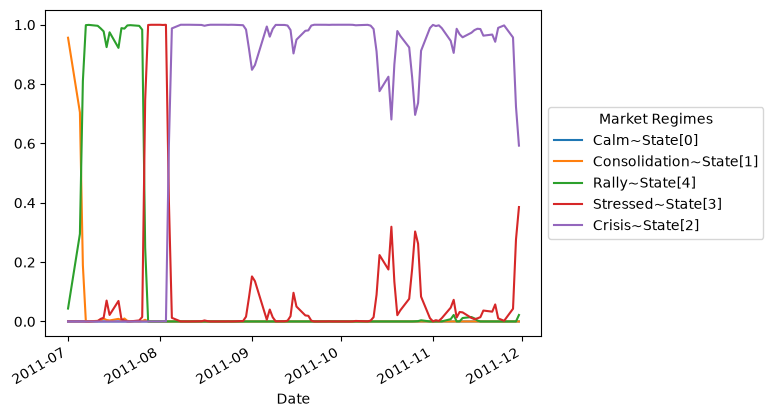

In [398]:
ax = P.loc['2011-07-01':'2011-11-30'].plot()
ax.legend(title="Market Regimes", 
          labels=["Calm~State[0]", "Consolidation~State[1]", "Rally~State[4]", "Stressed~State[3]", "Crisis~State[2]"],
          loc='center left', 
          bbox_to_anchor=(1.0, 0.5))

### Model Reaction and Trading Filter

The model reacted to changing market conditions by switching from Consolidation to Stressed around 28 March, then to Crisis on 4 April 2025. The regime filter disables trading during stressed and crisis states while allowing trades in the other states.

In this period, the filter would have stopped trading during the prolonged Stressed regime and remained off when Crisis was detected. This demonstrates a defensive response to heightened market uncertainty, helping avoid exposure during turbulent conditions, although it may also miss potential recovery gains.

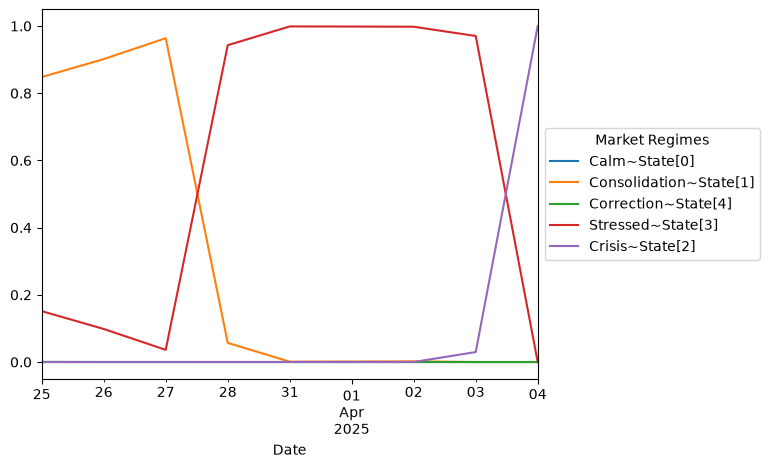

In [383]:
ax = P.loc['2025-03-25':'2025-04-05'].plot()
ax.legend(title="Market Regimes", 
          labels=["Calm~State[0]", "Consolidation~State[1]", "Correction~State[4]", "Stressed~State[3]", "Crisis~State[2]"],
          loc='center left', 
          bbox_to_anchor=(1.0, 0.5))

### Interpretation: Regime Filter During Historical Crises

The output shows the regime value on the left and its proportion on the right. A regime value of 0 means trading is switched off, while 1 means trading is allowed**.

During the 2020 COVID-19 Crash, the model was in regime 0 for approximately 92.3% of observations and regime 1 for only 7.7%. Therefore, the filter switched trading off for most of this period, demonstrating a defensive response to the market crash.

Similarly, during the 2022 Rate-Hike Bear Market, the model was in regime 0 for approximately 80.8% of observations and regime 1 for 19.2%.

Conclusion: The filter kept trading switched off during most observations in these periods, helping limit exposure to turbulent market conditions.

In [379]:
crisis_periods = {
    'Trump Tarrifs': ('2025-04-01', '2025-04-30'),
    '2008 Financial Crisis': ('2008-09-01', '2009-03-01'), '2010 Flash Crash': ('2010-05-01', '2010-05-10'),
    '2011 US Debt Downgrade / Euro Crisis': ('2011-07-01', '2011-10-15'),
    '2015-16 China Slowdown / Oil Crash': ('2015-08-01', '2016-02-15'),
    '2018 Q4 Selloff': ('2018-10-01', '2018-12-26'),
    '2022 Rate-Hike Bear Market': ('2022-01-01', '2022-10-15'),
    'Mid-2000s Bull Run': ('2003-06-01', '2007-06-01'),
    'Post-COVID Bull Run': ('2020-05-01', '2021-12-31'),
    '2023-24 AI-driven Rally': ('2023-06-01', '2024-12-31'),
    'COVID-19 Crash': ('2020-02-15', '2020-04-30')
}

state_series = pd.Series(regime, index=P.index)

for name, (start, end) in crisis_periods.items():
    period_states = state_series.loc[start:end]
    print(f"\n{name} ({start} to {end}), {len(period_states)} trading days:")
    print(period_states.value_counts(normalize=True).sort_values(ascending=False))


Trump Tarrifs (2025-04-01 to 2025-04-30), 21 trading days:
0.0    1.0
Name: proportion, dtype: float64

2008 Financial Crisis (2008-09-01 to 2009-03-01), 124 trading days:
0.0    1.0
Name: proportion, dtype: float64

2010 Flash Crash (2010-05-01 to 2010-05-10), 6 trading days:
0.0    0.666667
1.0    0.333333
Name: proportion, dtype: float64

2011 US Debt Downgrade / Euro Crisis (2011-07-01 to 2011-10-15), 74 trading days:
0.0    0.77027
1.0    0.22973
Name: proportion, dtype: float64

2015-16 China Slowdown / Oil Crash (2015-08-01 to 2016-02-15), 135 trading days:
1.0    0.540741
0.0    0.459259
Name: proportion, dtype: float64

2018 Q4 Selloff (2018-10-01 to 2018-12-26), 60 trading days:
0.0    0.716667
1.0    0.283333
Name: proportion, dtype: float64

2022 Rate-Hike Bear Market (2022-01-01 to 2022-10-15), 198 trading days:
0.0    0.808081
1.0    0.191919
Name: proportion, dtype: float64

Mid-2000s Bull Run (2003-06-01 to 2007-06-01), 0 trading days:
Series([], Name: proportion, dtyp